# SafeStep · 7 — Explainability (TreeSHAP) & error gallery
Exact SHAP values from LightGBM's built-in TreeSHAP (`pred_contrib`) — the same call the app uses live.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, sys, json, time, shutil, warnings
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import f1_score, confusion_matrix, average_precision_score, balanced_accuracy_score
warnings.filterwarnings('ignore')
BASE = '/content/drive/MyDrive/Daffodil Robo Tech Olympiad'
PROJ = f'{BASE}/SafeStep'
D = {k: f'{PROJ}/{k}' for k in ['data', 'artifacts', 'figures', 'models', 'code']}
DEPLOY = f"{D['models']}/deploy"; os.makedirs(DEPLOY, exist_ok=True)
sys.path.insert(0, D['code']); import safestep_core as core
SEED = 42; rng = np.random.default_rng(SEED)
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 110
def save_fig(name): plt.savefig(f"{D['figures']}/{name}.png", dpi=300, bbox_inches='tight')
FS, W = core.FS, core.WIN
F    = pd.read_parquet(f"{D['data']}/features_345.parquet").set_index('win_id')
wm   = pd.read_parquet(f"{D['data']}/windows_meta.parquet").set_index('win_id')
meta = pd.read_parquet(f"{D['data']}/trials_meta.parquet").set_index('trial_id')
SEL  = json.load(open(f"{D['artifacts']}/feature_selection.json"))
CFG  = json.load(open(f"{DEPLOY}/deploy_config.json"))
try:
    import lightgbm as lgb
    def make_model(): return lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1,
                                                colsample_bytree=0.8, class_weight='balanced', n_jobs=-1, random_state=SEED, verbose=-1)
except ImportError:
    def make_model(): return ExtraTreesClassifier(n_estimators=400, min_samples_leaf=2, class_weight='balanced', n_jobs=-1, random_state=SEED)
print(F.shape, '| deployed fall model:', CFG['fall_model'], '| activity model:', CFG['activity_model'])

(136051, 345) | deployed fall model: MLP | activity model: LightGBM


In [3]:
FEATS = CFG['features']
cat = pd.read_csv(f"{D['artifacts']}/feature_catalog.csv").set_index('feature')
lgb_path = f"{D['models']}/classical/fall__phone__LightGBM.joblib"
alt_path = f"{D['models']}/classical/fall__phone__ExtraTrees.joblib"
EXPL = joblib.load(lgb_path if os.path.exists(lgb_path) else alt_path)
EXACT = os.path.exists(lgb_path)
print('explanation model:', 'LightGBM (exact TreeSHAP)' if EXACT else 'ExtraTrees (approximate)')
def contrib(X):
    if EXACT: return EXPL.predict(X, pred_contrib=True)[:, :-1]
    imp = EXPL.feature_importances_; return (X - F[FEATS].values.mean(0)) * imp
te = wm[(wm.split == 'test') & (wm.y_fall >= 0)]
samp = pd.concat([te[te.y_fall == 1].sample(min(1500, (te.y_fall == 1).sum()), random_state=1),
                  te[te.y_fall == 0].sample(min(1500, (te.y_fall == 0).sum()), random_state=1)])
Xs = F.loc[samp.index, FEATS].values
SV = contrib(Xs)
p_expl = EXPL.predict_proba(Xs)[:, 1]
p_dep = joblib.load(f"{DEPLOY}/fall_model.joblib").predict_proba(Xs)[:, 1]
print(f'agreement with deployed {CFG["fall_model"]}: r = {np.corrcoef(p_expl, p_dep)[0, 1]:.3f}')

explanation model: LightGBM (exact TreeSHAP)
agreement with deployed MLP: r = 0.988


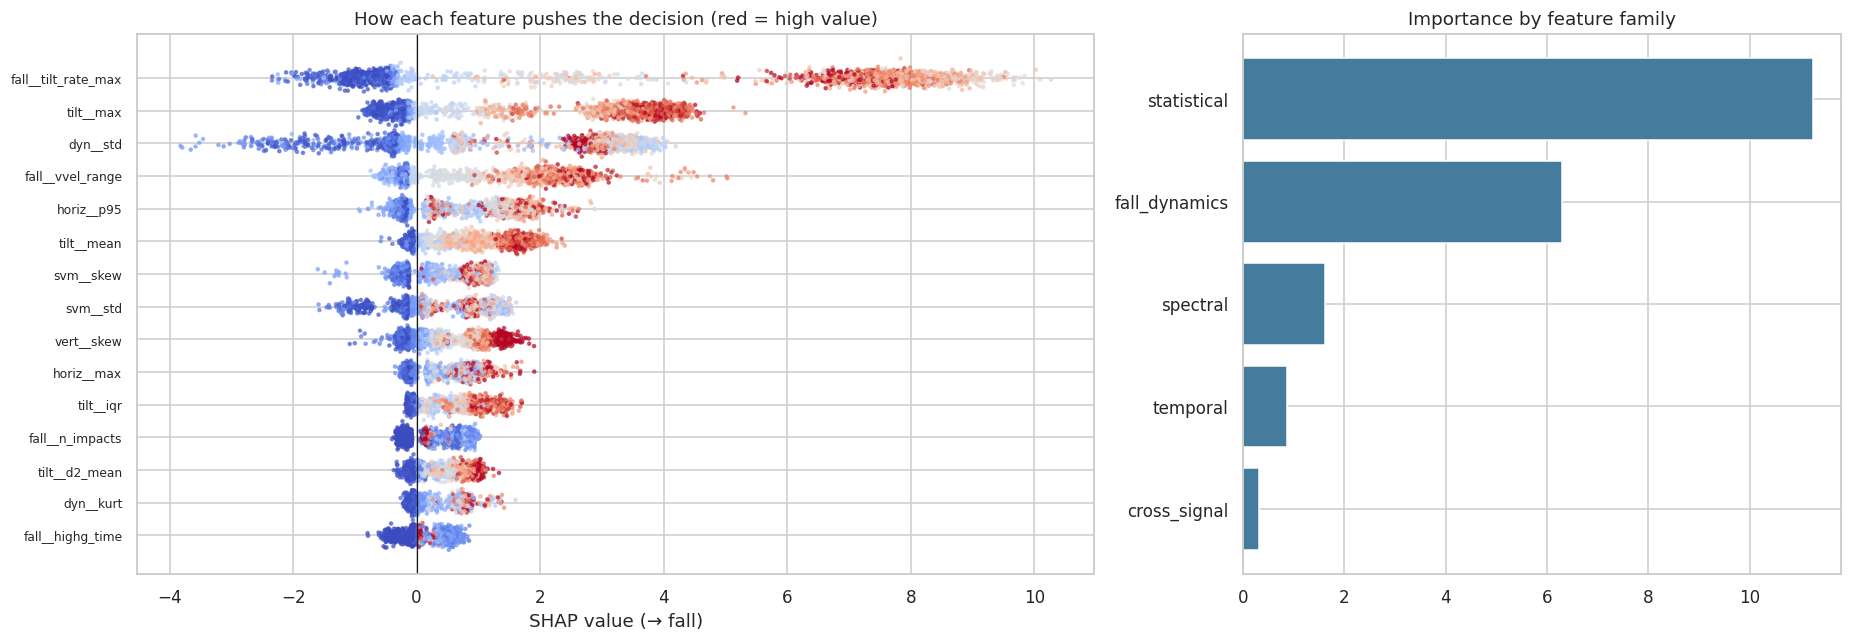

,feature,mean_abs_shap,group,signal
0,fall__tilt_rate_max,4.074716,fall_dynamics,multi
2,tilt__max,1.898816,statistical,tilt
9,dyn__std,1.755542,statistical,dyn
3,fall__vvel_range,1.086288,fall_dynamics,multi
7,horiz__p95,0.860813,statistical,horiz
4,tilt__mean,0.680639,statistical,tilt
25,svm__skew,0.636962,statistical,svm
11,svm__std,0.613088,statistical,svm
22,vert__skew,0.509510,statistical,vert
5,horiz__max,0.472219,statistical,horiz


In [4]:
GS = pd.DataFrame({'feature': FEATS, 'mean_abs_shap': np.abs(SV).mean(0)})
GS['group'] = cat.loc[GS.feature, 'group'].values; GS['signal'] = cat.loc[GS.feature, 'signal'].values
GS = GS.sort_values('mean_abs_shap', ascending=False)
top = GS.feature.head(15).tolist()[::-1]
fig, ax = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={'width_ratios': [1.6, 1]})
for i, f in enumerate(top):
    j = FEATS.index(f); v = Xs[:, j]; c = (v - np.percentile(v, 5)) / (np.percentile(v, 95) - np.percentile(v, 5) + 1e-9)
    ax[0].scatter(SV[:, j], i + rng.normal(0, 0.12, len(v)), c=np.clip(c, 0, 1), cmap='coolwarm', s=4, alpha=0.6)
ax[0].set_yticks(range(len(top))); ax[0].set_yticklabels(top, fontsize=8); ax[0].axvline(0, color='k', lw=0.8)
ax[0].set_xlabel('SHAP value (→ fall)'); ax[0].set_title('How each feature pushes the decision (red = high value)')
fam = GS.groupby('group').mean_abs_shap.sum().sort_values()
ax[1].barh(fam.index, fam.values, color='#457b9d'); ax[1].set_title('Importance by feature family')
plt.tight_layout(); save_fig('70_shap_global'); plt.show()
GS.head(15)

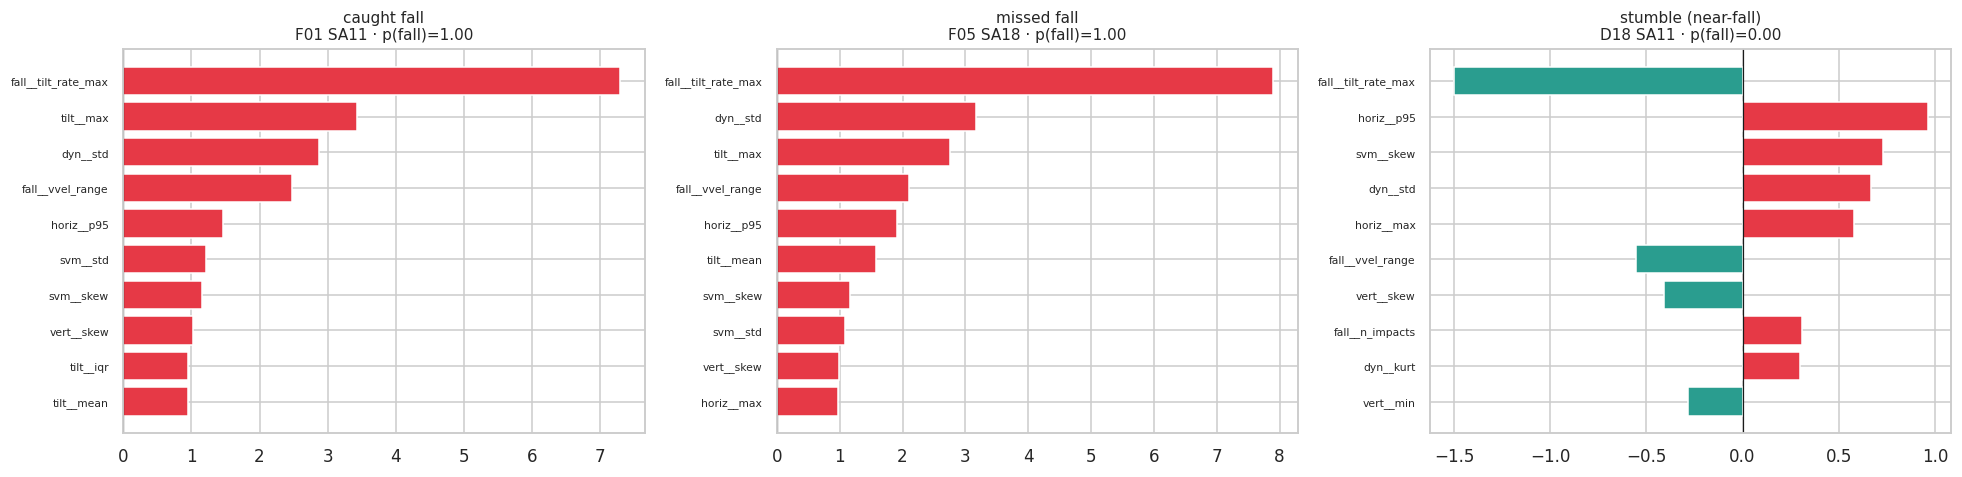

In [5]:
pr = pd.read_csv(f"{D['artifacts']}/final_stream_per_recording.csv")
def best_window(tid, target):
    w = wm[(wm.trial_id == tid)]
    if target == 'impact' and (w.phase == 'impact').any(): w = w[w.phase == 'impact']
    p = EXPL.predict_proba(F.loc[w.index, FEATS].values)[:, 1]
    return w.index[int(np.argmax(p))]
cases = []
c = pr[(pr.type == 'Fall') & pr.detected]
if len(c): cases.append(('caught fall', best_window(int(c.iloc[0].tid), 'impact')))
m = pr[(pr.type == 'Fall') & ~pr.detected]
if len(m): cases.append(('missed fall', best_window(int(m.iloc[0].tid), 'impact')))
nf = wm[(wm.split == 'test') & (wm.code == 'D18')]
if len(nf): cases.append(('stumble (near-fall)', best_window(int(nf.trial_id.iloc[0]), 'any')))
fig, axes = plt.subplots(1, len(cases), figsize=(6 * len(cases), 4.5))
axes = np.atleast_1d(axes)
for ax, (name, wid) in zip(axes, cases):
    x = F.loc[[wid], FEATS].values; s = contrib(x)[0]; o = np.argsort(-np.abs(s))[:10][::-1]
    ax.barh([FEATS[i] for i in o], s[o], color=['#e63946' if v > 0 else '#2a9d8f' for v in s[o]])
    ax.axvline(0, color='k', lw=0.8); ax.tick_params(axis='y', labelsize=7)
    ax.set_title(f"{name}\n{wm.loc[wid, 'code']} {wm.loc[wid, 'subject']} · p(fall)={EXPL.predict_proba(x)[0, 1]:.2f}", fontsize=10)
plt.tight_layout(); save_fig('71_shap_local_cases'); plt.show()

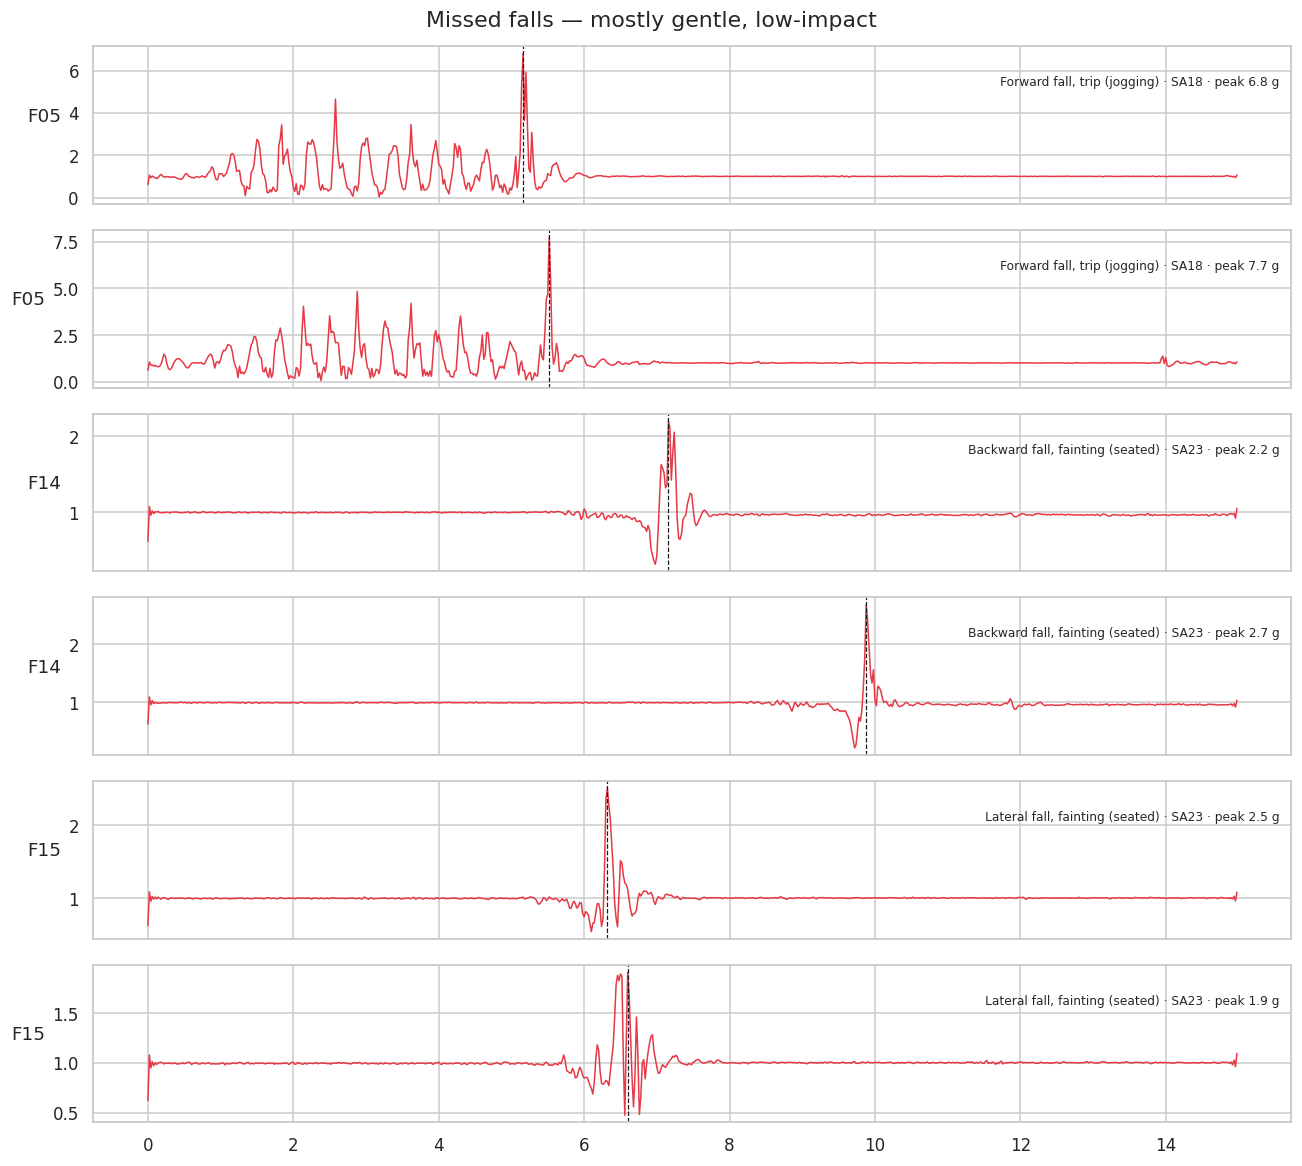

missed falls by type: {'F13': 4, 'F10': 4, 'F15': 3, 'F14': 2, 'F05': 2, 'F07': 1, 'F01': 1}


In [6]:
signals = np.load(f"{D['data']}/signals_50hz.npz")['signals']
miss = pr[(pr.type == 'Fall') & ~pr.detected].head(6)
if len(miss):
    fig, axes = plt.subplots(len(miss), 1, figsize=(12, 1.8 * len(miss)), sharex=True)
    for ax, r in zip(np.atleast_1d(axes), miss.itertuples()):
        mr = meta.loc[r.tid]; x = signals[mr.offset:mr.offset + mr.n_samples]
        ax.plot(np.arange(len(x)) / FS, np.linalg.norm(x[:, :3], axis=1), lw=1, color='#e63946')
        ax.axvline(mr.peak_idx / FS, color='k', ls='--', lw=0.8); ax.set_ylabel(mr.code, rotation=0, labelpad=16)
        ax.text(0.99, 0.75, f"{mr['name']} · {mr.subject} · peak {mr.peak_g:.1f} g", transform=ax.transAxes, ha='right', fontsize=8)
    plt.suptitle('Missed falls — mostly gentle, low-impact'); plt.tight_layout(); save_fig('72_missed_falls'); plt.show()
print('missed falls by type:', pr[(pr.type == 'Fall') & ~pr.detected].code.value_counts().to_dict())

In [7]:
GS.to_csv(f"{D['artifacts']}/shap_global.csv", index=False)
joblib.dump(EXPL, f'{DEPLOY}/explain_model.joblib', compress=3)
json.dump({'features': FEATS, 'exact_treeshap': EXACT, 'feature_mean': F[FEATS].values.mean(0).tolist()},
          open(f'{DEPLOY}/explain_config.json', 'w'), indent=2)
print('saved shap_global.csv + explain model')

saved shap_global.csv + explain model
